# CYB-5 · Experiment 30 — Fine-tune DistilBERT on phishing emails

**Purpose:** Compare a task-fine-tuned Transformer to the frozen MiniLM and TF-IDF classifiers. Colab Tesla T4 recommended. **Data:** use the same fixed template-aware train (1,307), validation (277), test (316), original exploratory (100) partitions.

**Research integrity:** Train only on `train`; choose epoch and threshold only with `validation`. The held-out `test` has already been examined in prior experiments, so this comparison is **exploratory**, not an unbiased final test. Do not tune to test errors. Generated template-labeled data are not a substitute for independent real-world phishing email evaluation. TREC labels may represent spam, not strictly phishing.

**Run top to bottom.** This notebook detects your Colab GPU, finds data in a Colab runtime directory or Google Drive, fine-tunes DistilBERT, reports metrics and exports results.

## 1 · Install dependencies

In [1]:
%pip -q install "transformers>=4.45,<5" "accelerate>=0.27" "pyarrow>=14" "scikit-learn>=1.3" pandas matplotlib joblib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 2 · GPU and random seed

In [2]:
import json, random, shutil, zipfile, sys
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Python:', sys.version.split()[0]); print('PyTorch:', torch.__version__)
print('Device:', DEVICE)
if DEVICE.type == 'cuda': print('GPU:', torch.cuda.get_device_name(0))


Python: 3.13.16
PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


## 3 · Locate the four Parquet datasets

The Colab GPU cannot read `D:\CYB5` directly even when opened from VS Code. Put the four files together in either `/content/` (session storage) or `MyDrive/CYB5/` (mounted Google Drive). **This cell does not use `files.upload()`** because that widget can fail inside VS Code.

To use Drive, run `from google.colab import drive; drive.mount('/content/drive')` in a separate cell if not already mounted. You may instead upload through Colab's browser Files sidebar to `/content/`.

In [3]:
from pathlib import Path
FILES = ['train.parquet', 'validation.parquet', 'test.parquet', 'original_exploratory.parquet']
CANDIDATES = [
    Path('/content'),
    Path('/content/CYB5'),
    Path('/content/drive/MyDrive/CYB5'),
    Path('/content/drive/MyDrive/CYB5/data/phishing_validation/processed'),
    Path.cwd(),
]
DATA_DIR = next((d for d in CANDIDATES if all((d/f).is_file() for f in FILES)), None)
if DATA_DIR is None:
    print('Searched locations:')
    for d in CANDIDATES:
        print(' ', d, 'exists:', d.exists(), 'files:', [f for f in FILES if (d/f).is_file()])
    raise FileNotFoundError('Place ALL FOUR Parquet files together in /content or MyDrive/CYB5, then rerun this cell.')
print('Datasets found at:', DATA_DIR)
for f in FILES: print(f, (DATA_DIR/f).stat().st_size, 'bytes')


Datasets found at: /content/drive/MyDrive/CYB5
train.parquet 167176 bytes
validation.parquet 36646 bytes
test.parquet 41326 bytes
original_exploratory.parquet 14211 bytes


## 4 · Validate data, classes, templates, and hashes

In [4]:
sets = {key: pd.read_parquet(DATA_DIR / f'{key}.parquet') for key in ['train','validation','test','original_exploratory']}
expected = {'train':1307,'validation':277,'test':316,'original_exploratory':100}
for name, df in sets.items():
    required = {'text', 'label', 'template_id', 'text_hash'}
    if not required.issubset(df.columns):
        raise ValueError(f'{name}: missing columns {required-set(df.columns)}')
    if df[['text','label','template_id','text_hash']].isna().any().any():
        raise ValueError(f'{name}: null in required columns')
    if not set(df['label'].unique()).issubset({0,1}):
        raise ValueError(f'{name}: bad labels')
    assert len(df) == expected[name], f'{name}: unexpected row count'
    print(name, len(df), 'labels', df.label.value_counts().to_dict(), 'templates', df.template_id.nunique())
for a,b in [('train','validation'),('train','test'),('validation','test')]:
    assert set(sets[a].template_id).isdisjoint(set(sets[b].template_id)), f'template leakage: {a}/{b}'
    assert set(sets[a].text_hash).isdisjoint(set(sets[b].text_hash)), f'exact hash overlap: {a}/{b}'
print('PASSED: train / validation / test template and exact-text separation')


train 1307 labels {1: 675, 0: 632} templates 36
validation 277 labels {1: 143, 0: 134} templates 8
test 316 labels {1: 159, 0: 157} templates 8
original_exploratory 100 labels {0: 77, 1: 23} templates 1
PASSED: train / validation / test template and exact-text separation


## 5 · DistilBERT tokenizer and sequence length audit

In [5]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
MODEL_ID = 'distilbert/distilbert-base-uncased'
MAX_LENGTH = 256
BATCH_SIZE = 16
EPOCHS = 3
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
for name, df in sets.items():
    lengths = [len(ids) for ids in tokenizer(df.text.astype(str).tolist(), add_special_tokens=True, truncation=False)['input_ids']]
    print(f'{name}: max token length = {max(lengths)}, over {MAX_LENGTH} = {sum(v>MAX_LENGTH for v in lengths)}/{len(lengths)}')


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

train: max token length = 57, over 256 = 0/1307
validation: max token length = 54, over 256 = 0/277
test: max token length = 58, over 256 = 0/316
original_exploratory: max token length = 25, over 256 = 0/100


## 6 · Tokenization and batches

In [6]:
from torch.utils.data import Dataset, DataLoader
from transformers import DataCollatorWithPadding

class EmailDataset(Dataset):
    def __init__(self, frame):
        self.labels = frame.label.astype(int).tolist()
        self.encoded = tokenizer(frame.text.astype(str).tolist(), truncation=True, max_length=MAX_LENGTH)
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        item = {key: vals[i] for key, vals in self.encoded.items()}
        item['labels'] = self.labels[i]
        return item

collator = DataCollatorWithPadding(tokenizer=tokenizer, return_tensors='pt')
loaders = {name: DataLoader(EmailDataset(df), batch_size=BATCH_SIZE, shuffle=(name=='train'), collate_fn=collator, num_workers=0) for name,df in sets.items()}
print('Batches:', {k:len(v) for k,v in loaders.items()})


Batches: {'train': 82, 'validation': 18, 'test': 20, 'original_exploratory': 7}


## 7 · Fine-tune using training data; select best epoch by validation F1 at 0.50

In [7]:
from torch.optim import AdamW

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID, num_labels=2,
    id2label={0:'SAFE', 1:'PHISHING'}, label2id={'SAFE':0, 'PHISHING':1}
).to(DEVICE)
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
total_steps = len(loaders['train'])*EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=max(1,int(0.1*total_steps)), num_training_steps=total_steps)

def predict_probs(loader):
    model.eval(); probs=[]; ys=[]
    with torch.inference_mode():
        for batch in loader:
            labels = batch.pop('labels')
            inputs = {k:v.to(DEVICE) for k,v in batch.items()}
            logits = model(**inputs).logits
            probs.extend(torch.softmax(logits,dim=1)[:,1].cpu().tolist())
            ys.extend(labels.cpu().tolist())
    return np.asarray(ys,dtype=int), np.asarray(probs,dtype=float)

run_dir = Path('/content/cyb5_distilbert_experiment30')
run_dir.mkdir(parents=True, exist_ok=True)
best_f1 = -1.0; best_epoch = None; history=[]
for epoch in range(1, EPOCHS+1):
    model.train(); losses=[]
    for batch in loaders['train']:
        batch = {k:v.to(DEVICE) for k,v in batch.items()}
        optimizer.zero_grad(set_to_none=True)
        loss = model(**batch).loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
        optimizer.step(); scheduler.step()
        losses.append(loss.item())
    yv,pv = predict_probs(loaders['validation'])
    val_f1 = f1_score(yv,(pv>=0.5).astype(int),zero_division=0)
    row = {'epoch':epoch,'train_loss':float(np.mean(losses)),'validation_f1_at_0.5':float(val_f1)}
    history.append(row)
    print('Epoch',epoch,'loss',round(row['train_loss'],5),'validation F1 @0.50',round(val_f1,5))
    if val_f1 > best_f1:
        best_f1 = val_f1; best_epoch = epoch
        model.save_pretrained(run_dir/'best_model')
        tokenizer.save_pretrained(run_dir/'best_model')
print('Best epoch from validation:',best_epoch)
pd.DataFrame(history).to_csv(run_dir/'training_history.csv',index=False)


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch 1 loss 0.23748 validation F1 @0.50 1.0
Epoch 2 loss 0.00393 validation F1 @0.50 1.0
Epoch 3 loss 0.00237 validation F1 @0.50 1.0
Best epoch from validation: 1


## 8 · Select classification threshold using validation ONLY

In [8]:
model = AutoModelForSequenceClassification.from_pretrained(run_dir/'best_model').to(DEVICE)
yv,pv = predict_probs(loaders['validation'])
threshold_grid=[]
for th in np.round(np.arange(0.10,0.91,0.01),2):
    yp=(pv>=th).astype(int)
    threshold_grid.append({'threshold':float(th),'f1':float(f1_score(yv,yp,zero_division=0)), 'fpr':float(((yp==1)&(yv==0)).sum()/max(1,(yv==0).sum()))})
threshold_df=pd.DataFrame(threshold_grid)
threshold_df['distance_from_half']=(threshold_df.threshold-0.5).abs()
choice=threshold_df.sort_values(['f1','distance_from_half'],ascending=[False,True]).iloc[0]
THRESHOLD=float(choice.threshold)
threshold_df.drop(columns=['distance_from_half']).to_csv(run_dir/'validation_threshold_grid.csv',index=False)
print('Selected validation threshold:',THRESHOLD,'validation F1:',round(float(choice.f1),4))


Selected validation threshold: 0.5 validation F1: 1.0


## 9 · One-shot exploratory evaluation; DO NOT retune using test

In [9]:
def evaluate(name):
    y,p=predict_probs(loaders[name]); yp=(p>=THRESHOLD).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,yp,labels=[0,1]).ravel()
    metrics={'dataset':name,'samples':int(len(y)),'threshold':THRESHOLD,
        'accuracy':float(accuracy_score(y,yp)),
        'precision':float(precision_score(y,yp,zero_division=0)),
        'recall':float(recall_score(y,yp,zero_division=0)),
        'f1':float(f1_score(y,yp,zero_division=0)),
        'fpr':float(fp/(fp+tn)) if fp+tn else None,
        'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)}
    print('\n===',name.upper(),'===')
    print(classification_report(y,yp,labels=[0,1],target_names=['Safe','Phishing'],zero_division=0))
    print('Confusion matrix:',[[int(tn),int(fp)],[int(fn),int(tp)]])
    return metrics, y,p,yp

metrics={}; predictions={}
for name in ['train','validation','test','original_exploratory']:
    met,y,p,yp=evaluate(name)
    metrics[name]=met; predictions[name]=(y,p,yp)
summary=pd.DataFrame(list(metrics.values()))
print('\n=== OVERALL SUMMARY ===')
print(summary[['dataset','samples','accuracy','precision','recall','f1','fpr','fp','fn']].round(4).to_string(index=False))
summary.to_csv(run_dir/'distilbert_metrics.csv',index=False)
(run_dir/'distilbert_metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')



=== TRAIN ===
              precision    recall  f1-score   support

        Safe       1.00      1.00      1.00       632
    Phishing       1.00      1.00      1.00       675

    accuracy                           1.00      1307
   macro avg       1.00      1.00      1.00      1307
weighted avg       1.00      1.00      1.00      1307

Confusion matrix: [[632, 0], [0, 675]]

=== VALIDATION ===
              precision    recall  f1-score   support

        Safe       1.00      1.00      1.00       134
    Phishing       1.00      1.00      1.00       143

    accuracy                           1.00       277
   macro avg       1.00      1.00      1.00       277
weighted avg       1.00      1.00      1.00       277

Confusion matrix: [[134, 0], [0, 143]]

=== TEST ===
              precision    recall  f1-score   support

        Safe       1.00      1.00      1.00       157
    Phishing       1.00      1.00      1.00       159

    accuracy                           1.00       316
 

998

## 10 · Per-template errors and confusion matrix chart

      template_id  label  samples  accuracy  mean_phishing_probability
 PHISH_ACCT_LOGIN      1       42       1.0                     0.9953
   PHISH_ACCT_PWD      1       35       1.0                     0.9952
PHISH_PAY_DECLINE      1       38       1.0                     0.9956
  PHISH_VISH_SUSP      1       44       1.0                     0.9867
      SAFE_AGENDA      0       35       1.0                     0.0056
       SAFE_ANNIV      0       40       1.0                     0.0063
  SAFE_ORDER_CONF      0       41       1.0                     0.0073
   SAFE_WIKI_LINK      0       41       1.0                     0.0088


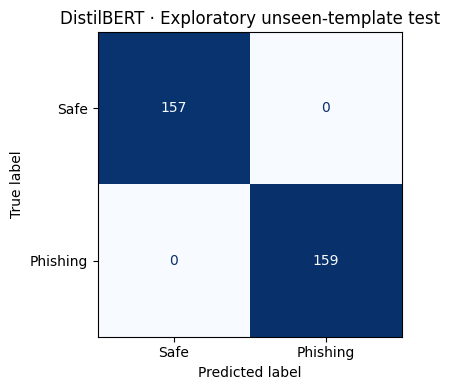

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

y,p,yp=predictions['test']
temp=sets['test'][['template_id','label']].copy()
temp['prediction']=yp; temp['probability']=p; temp['correct']=(yp==y)
template_summary=temp.groupby(['template_id','label']).agg(samples=('correct','size'),accuracy=('correct','mean'),mean_phishing_probability=('probability','mean')).reset_index()
print(template_summary.round(4).to_string(index=False))
template_summary.to_csv(run_dir/'distilbert_by_template.csv',index=False)
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(y,yp,display_labels=['Safe','Phishing'],cmap='Blues',ax=ax,colorbar=False)
ax.set_title('DistilBERT · Exploratory unseen-template test')
fig.tight_layout(); fig.savefig(run_dir/'distilbert_test_confusion_matrix.png',dpi=170);plt.show()


## 11 · Export metrics ZIP; save optional trained-model weights separately

In [11]:
config={'experiment':30,'encoder':MODEL_ID,'seed':SEED,'epochs':EPOCHS,'best_epoch':best_epoch,
'lr':LEARNING_RATE,'batch_size':BATCH_SIZE,'max_length':MAX_LENGTH,'threshold':THRESHOLD,
'split_protocol':'fixed template-separated synthetic data',
'warning':'The test templates have previously been examined; exploratory comparison only. Do not tune to this test.'}
(run_dir/'experiment_config.json').write_text(json.dumps(config,indent=2),encoding='utf-8')
zip_path=Path('/content/CYB5_DistilBERT_Results.zip')
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for path in run_dir.iterdir():
        if path.is_file(): z.write(path,arcname=path.name)
print('Results ZIP created:',zip_path,'size MB:',round(zip_path.stat().st_size/1e6,2))
print('Full fine-tuned model saved at:',run_dir/'best_model')
print('IMPORTANT: model weights are not in the small results ZIP.')
# If Drive is mounted, make persistent copy without relying on browser download widgets.
mydrive=Path('/content/drive/MyDrive')
if mydrive.is_dir():
    dest=mydrive/'CYB5_DistilBERT_Results.zip'; shutil.copy2(zip_path,dest)
    print('Results ZIP also copied to MyDrive as:',dest.name)
else:
    print('Google Drive not mounted. Download ZIP from Colab Files panel before runtime disconnects.')


Results ZIP created: /content/CYB5_DistilBERT_Results.zip size MB: 0.03
Full fine-tuned model saved at: /content/cyb5_distilbert_experiment30/best_model
IMPORTANT: model weights are not in the small results ZIP.
Results ZIP also copied to MyDrive as: CYB5_DistilBERT_Results.zip


## What to capture for your report

- **Capture 51:** T4 GPU and data partition verification.
- **Capture 52:** DistilBERT token lengths and training history (all epochs).
- **Capture 53:** Validation-selected threshold and metrics summary.
- **Capture 54:** Exploratory test confusion matrix and per-template diagnosis.

**After running:** Share the metrics summary and confusion matrix. We will compare DistilBERT to TF-IDF and MiniLM, note correlated template errors, and design a genuinely independent holdout for final reporting. If you need to preserve the fine-tuned DistilBERT model, copy the entire `best_model` directory to Drive before the Colab session ends.

In [13]:

from pathlib import Path
import shutil

model_dir = Path("/content/cyb5_distilbert_experiment30/best_model")

print("Model exists:", model_dir.exists())

if model_dir.is_dir():
    print("Model files:", [p.name for p in model_dir.iterdir()])

    zip_file = shutil.make_archive(
        "/content/CYB5_DistilBERT_Model",
        "zip",
        root_dir=model_dir
    )

    drive_file = Path(
        "/content/drive/MyDrive/CYB5_DistilBERT_Model.zip"
    )

    shutil.copy2(zip_file, drive_file)

    print("MODEL SAVED SUCCESSFULLY")
    print("Size:", round(drive_file.stat().st_size / 1048576, 2), "MB")
else:
    print("Model folder not found in this runtime.")


Model exists: True
Model files: ['tokenizer_config.json', 'special_tokens_map.json', 'tokenizer.json', 'config.json', 'vocab.txt', 'model.safetensors']
MODEL SAVED SUCCESSFULLY
Size: 235.85 MB
